# **Step 1:Import libraries and load the data**

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
df=pd.read_csv("/content/loan_default.csv")
print(df.head())
print(df.info())
print(df.shape)

  customer_id  age   income  loan_amount  credit_score  employment_years  \
0   CUST00084   59  52055.0      67855.0         589.0               8.1   
1   CUST00543   58  48605.0     187963.0         641.0              20.4   
2   CUST00718   29  54590.0     244551.0         726.0               0.8   
3   CUST00240   56  18951.0     561210.0         726.0              27.0   
4   CUST00649   37  76183.0     187744.0         658.0              10.1   

   debt_to_income  existing_loans  dependents  bank_balance  interest_rate  \
0           0.436               0           4       1841.31          10.75   
1           0.030               0           1          0.00          11.67   
2           0.484               0           0        794.75           8.13   
3           0.043               0           1      17515.85           8.63   
4           0.412               1           3      10617.61           8.47   

  employment_type marital_status      education loan_purpose city_tier  \


**`Ques-How many rows and columns are there? Which columns are numeric and which are categorical?`**

**Sol--** The dataset contains 1,012 rows and 18 columns before cleaning. Numeric columns include age, income, loan_amount, credit_score, employment_years, debt_to_income, existing_loans, dependents, bank_balance, interest_rate, and previous_defaults. Categorical columns include employment_type, marital_status, education, loan_purpose, city_tier, and loan_default. The customer_id column is an identifier and should not be used as a feature.

# **Step 2:Understand the data**

,age,income,loan_amount,credit_score,employment_years,debt_to_income,existing_loans,dependents,bank_balance,interest_rate,previous_defaults
count,1012.000000,1012.000000,1012.000000,1012.000000,1012.000000,1012.000000,1012.000000,1012.000000,1012.000000,1012.000000,1012.000000
mean,42.669960,54157.542490,246006.705534,651.821146,9.994763,0.368216,0.996047,1.936759,8107.384951,9.325702,0.254941
std,13.986137,21295.031417,116654.104628,79.549937,7.718507,0.154261,0.979505,1.390213,6095.294697,1.424837,0.499481
min,-52.000000,-74577.000000,20000.000000,411.000000,0.000000,0.020000,0.000000,0.000000,0.000000,6.000000,0.000000
25%,32.000000,40859.000000,169464.500000,596.750000,3.875000,0.263000,0.000000,1.000000,3086.785000,8.370000,0.000000
50%,43.000000,53837.500000,242872.000000,651.500000,7.900000,0.371000,1.000000,2.000000,7747.690000,9.270000,0.000000
75%,54.000000,68032.750000,324349.500000,705.000000,14.525000,0.475250,2.000000,3.000000,12158.522500,10.252500,0.000000
max,64.000000,111578.000000,667635.000000,900.000000,33.600000,0.895000,4.000000,4.000000,34342.240000,14.880000,3.000000



customer_id:
customer_id
CUST00447    2
CUST00930    2
CUST00508    2
CUST00819    2
CUST00369    2
            ..
CUST00117    1
CUST00069    1
CUST00388    1
CUST00804    1
CUST00601    1
Name: count, Length: 1000, dtype: int64

employment_type:
employment_type
Salaried         463
Self-employed    220
Business         186
Contract         143
Name: count, dtype: int64

marital_status:
marital_status
Married     517
Single      409
Divorced     86
Name: count, dtype: int64

education:
education
Undergraduate    377
Graduate         276
High School      183
Postgraduate     115
NaN               61
Name: count, dtype: int64

loan_purpose:
loan_purpose
Home         340
Personal     270
Business     247
Education    155
Name: count, dtype: int64

city_tier:
city_tier
Tier 1    416
Tier 2    350
Tier 3    246
Name: count, dtype: int64

loan_default:
loan_default
No     825
Yes    187
Name: count, dtype: int64


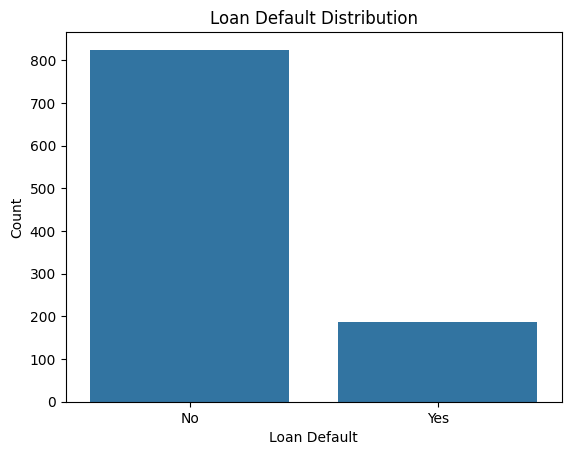

In [ ]:
# Summary statistics for numeric columns
display(df.describe())

# Value counts for categorical columns
categorical_cols = df.select_dtypes(include='object').columns

for col in categorical_cols:
    print(f"\n{col}:")
    print(df[col].value_counts(dropna=False))

# Count plot of loan_default
sns.countplot(data=df, x='loan_default')
plt.title('Loan Default Distribution')
plt.xlabel('Loan Default')
plt.ylabel('Count')
plt.show()

**`Question--Is the target balanced, or are there far more Yes than No (or the reverse)? Why might this matter?`**

**Sol--** The target variable is imbalanced because 825 customers (81.52%) did not default, while 187 customers (18.48%) defaulted. This imbalance may cause the model to favor the majority class. Therefore, accuracy alone may not be sufficient to evaluate the model, and recall, precision, and F1-score should also be considered.

# **Step 3:Clean the data**

In [ ]:
# Check missing values
print("Missing values:")
print(df.isnull().sum())

# Fill missing categorical values with the most frequent value
df['education'] = df['education'].fillna(df['education'].mode()[0])

# Check and remove duplicate rows
print("Duplicate rows:", df.duplicated().sum())
df = df.drop_duplicates()

# Check impossible values
print("Negative ages:", (df['age'] < 0).sum())
print("Negative incomes:", (df['income'] < 0).sum())

# Remove rows with negative ages or incomes
df = df[(df['age'] >= 0) & (df['income'] >= 0)]

# Verify cleaned data
print("\nMissing values after cleaning:")
print(df.isnull().sum())

print("\nDataset shape after cleaning:", df.shape)

Missing values:
customer_id           0
age                   0
income                0
loan_amount           0
credit_score          0
employment_years      0
debt_to_income        0
existing_loans        0
dependents            0
bank_balance          0
interest_rate         0
employment_type       0
marital_status        0
education            61
loan_purpose          0
city_tier             0
previous_defaults     0
loan_default          0
dtype: int64
Duplicate rows: 11
Negative ages: 5
Negative incomes: 5

Missing values after cleaning:
customer_id          0
age                  0
income               0
loan_amount          0
credit_score         0
employment_years     0
debt_to_income       0
existing_loans       0
dependents           0
bank_balance         0
interest_rate        0
employment_type      0
marital_status       0
education            0
loan_purpose         0
city_tier            0
previous_defaults    0
loan_default         0
dtype: int64

Dataset shape after cle

**`Question-- Which columns had missing values, and what did you do about them? Why did you choose that method.`**

**Sol--** The education column contained 61 missing values, which were filled using the most frequent category. Duplicate rows were checked and removed. Negative ages and incomes were also checked, and rows containing these impossible values were removed. These steps improve data quality before model training.

# **Step 4: the data visually**

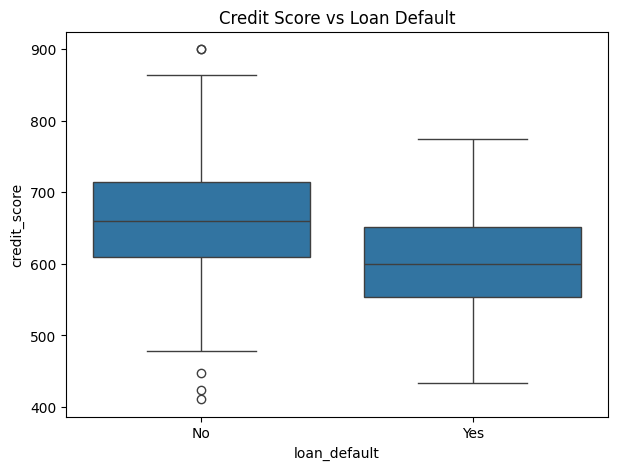

In [ ]:

plt.figure(figsize=(7, 5))
sns.boxplot(data=df, x='loan_default', y='credit_score')
plt.title('Credit Score vs Loan Default')
plt.show()


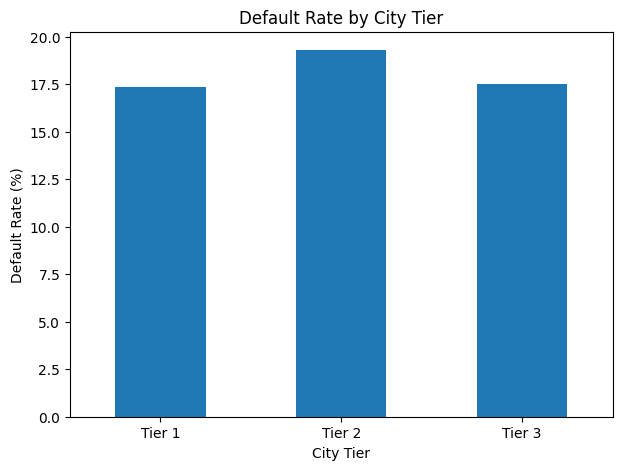

In [ ]:

plt.figure(figsize=(7, 5))

city_default_rate = df.groupby('city_tier')['loan_default'].apply(
    lambda x: (x == 'Yes').mean() * 100
)

city_default_rate.plot(kind='bar')
plt.title('Default Rate by City Tier')
plt.xlabel('City Tier')
plt.ylabel('Default Rate (%)')
plt.xticks(rotation=0)
plt.show()


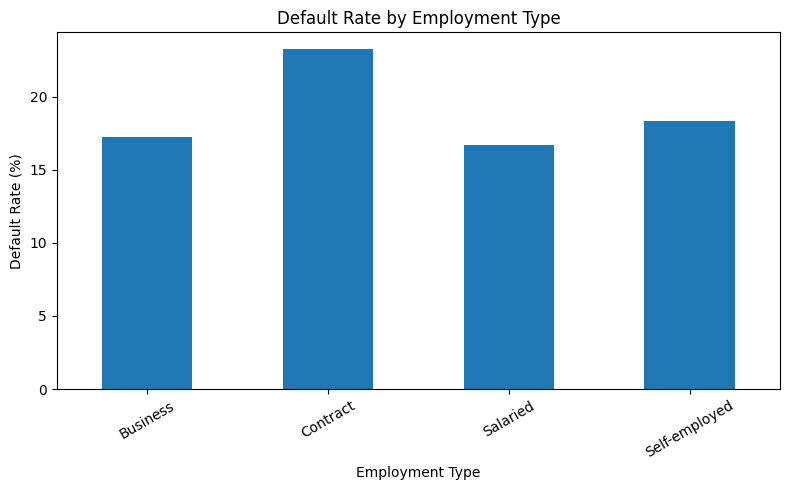

In [ ]:

plt.figure(figsize=(8, 5))

employment_default_rate = df.groupby('employment_type')['loan_default'].apply(
    lambda x: (x == 'Yes').mean() * 100
)

employment_default_rate.plot(kind='bar')
plt.title('Default Rate by Employment Type')
plt.xlabel('Employment Type')
plt.ylabel('Default Rate (%)')
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()


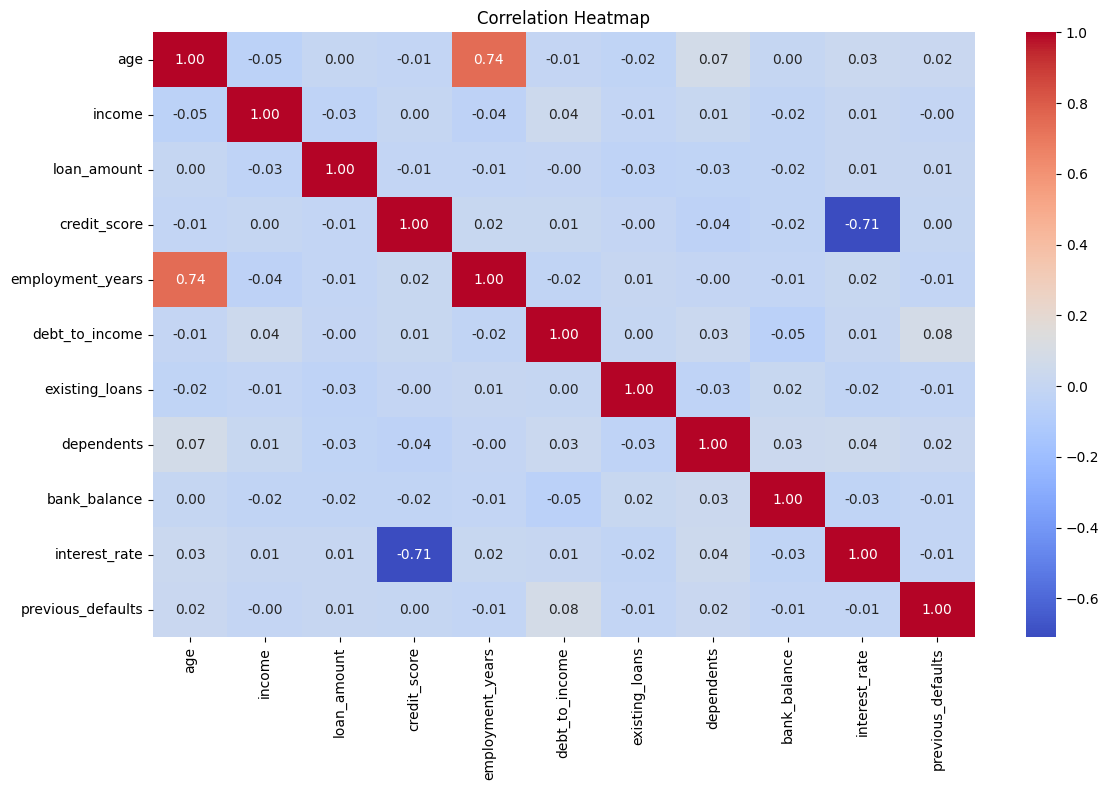

In [ ]:

numeric_df = df.select_dtypes(include=np.number)

plt.figure(figsize=(12, 8))
sns.heatmap(
    numeric_df.corr(),
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)
plt.title('Correlation Heatmap')
plt.tight_layout()
plt.show()


**`Question--Which two features appear to separate defaulters from non-defaulters best?`**

**Sol--** The boxplot of credit_score and the default-rate plots by city_tier and employment_type were used to explore differences between defaulters and non-defaulters. The two features that separate the groups best should be identified from the actual plots, based on the clearest differences in distributions or default rates.

# **Step 5:Prepare the data for modelling**

In [ ]:
# Drop customer_id
df = df.drop(columns=['customer_id'])

# Convert target column into numbers
df['loan_default'] = df['loan_default'].map({'Yes': 1, 'No': 0})

# Convert categorical columns into numeric columns
df = pd.get_dummies(df, drop_first=True, dtype=int)

# Separate features and target
X = df.drop('loan_default', axis=1)
y = df['loan_default']

print("Features shape:", X.shape)
print("Target shape:", y.shape)

display(X.head())

Features shape: (991, 24)
Target shape: (991,)


,age,income,loan_amount,credit_score,employment_years,debt_to_income,existing_loans,dependents,bank_balance,interest_rate,...,marital_status_Married,marital_status_Single,education_High School,education_Postgraduate,education_Undergraduate,loan_purpose_Education,loan_purpose_Home,loan_purpose_Personal,city_tier_Tier 2,city_tier_Tier 3
0,59,52055.0,67855.0,589.0,8.1,0.436,0,4,1841.31,10.75,...,1,0,1,0,0,0,0,0,0,1
1,58,48605.0,187963.0,641.0,20.4,0.030,0,1,0.00,11.67,...,0,1,0,0,0,1,0,0,0,0
2,29,54590.0,244551.0,726.0,0.8,0.484,0,0,794.75,8.13,...,1,0,1,0,0,0,0,1,0,0
3,56,18951.0,561210.0,726.0,27.0,0.043,0,1,17515.85,8.63,...,0,1,1,0,0,1,0,0,0,0
4,37,76183.0,187744.0,658.0,10.1,0.412,1,3,10617.61,8.47,...,1,0,0,0,1,1,0,0,0,0


***Question--Why can't a Decision Tree use text columns directly?***

Ans-- Scikit-learn Decision Trees require input features in numerical form. Text categories such as employment_type and education must be converted into numbers using techniques such as one-hot encoding with pd.get_dummies(). This allows the model to process categorical information and make predictions.

# **Step 6: Split into training and test sets**

In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    stratify=y,
    random_state=42
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

Training features: (792, 24)
Testing features: (199, 24)
Training target: (792,)
Testing target: (199,)


***Question--Why do we keep a test set aside?***

Ans--We keep a separate test set to evaluate the model on unseen data. The model is trained using the training set, while the test set measures how well it generalizes to new customers. We do not train on the test set because this could lead to biased evaluation and an unrealistic estimate of performance.

# **Step 7: Train a Decision Tree**

In [ ]:
from sklearn.tree import DecisionTreeClassifier

# Train the Decision Tree model
dt = DecisionTreeClassifier(random_state=42)
dt.fit(X_train, y_train)

# Predict on training and test sets
y_train_pred = dt.predict(X_train)
y_test_pred = dt.predict(X_test)

# Calculate accuracy
train_accuracy = dt.score(X_train, y_train)
test_accuracy = dt.score(X_test, y_test)

print("Training Accuracy:", train_accuracy)
print("Testing Accuracy:", test_accuracy)

Training Accuracy: 1.0
Testing Accuracy: 0.7336683417085427


***Question-- Is there a big gap between training and test accuracy?***

Ans--The difference between training accuracy and test accuracy indicates whether the model is overfitting. If training accuracy is much higher than test accuracy, the model is likely overfitting and may not generalize well to unseen data. The actual accuracy values should be used to determine the size of the gap.

# **Step 8: Evaluate the model properly**

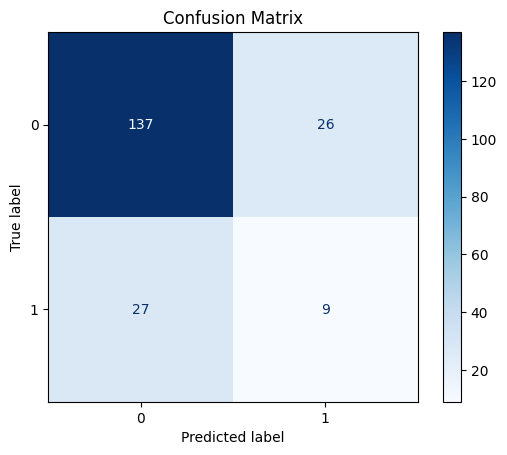

Classification Report:
              precision    recall  f1-score   support

           0       0.84      0.84      0.84       163
           1       0.26      0.25      0.25        36

    accuracy                           0.73       199
   macro avg       0.55      0.55      0.55       199
weighted avg       0.73      0.73      0.73       199

ROC-AUC Score: 0.5452453987730062


In [ ]:
from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report,
    roc_auc_score
)

# Confusion matrix
cm = confusion_matrix(y_test, y_test_pred)

disp = ConfusionMatrixDisplay(confusion_matrix=cm)
disp.plot(cmap='Blues')
plt.title('Confusion Matrix')
plt.show()

# Classification report
print("Classification Report:")
print(classification_report(y_test, y_test_pred))

# ROC-AUC score
y_test_prob = dt.predict_proba(X_test)[:, 1]
print("ROC-AUC Score:", roc_auc_score(y_test, y_test_prob))

***Question--In loan default prediction, which is worse: approving a loan that defaults, or rejecting a good customer? Which metric does this make most important?***

Ans-- Approving a loan to a customer who later defaults can cause financial losses for the bank. Rejecting a good customer also results in a missed business opportunity. For reducing default-related losses, recall for the default class is especially important because it measures how many actual defaulters the model correctly identifies. Precision should also be considered to avoid incorrectly flagging too many good customers.

# **Step 9: Control overfitting by tuning**

In [ ]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import GridSearchCV

# Test different max_depth values
for depth in [3, 5, 7, 10]:
    model = DecisionTreeClassifier(max_depth=depth, random_state=42)
    model.fit(X_train, y_train)

    print(f"Max Depth: {depth}")
    print("Training Accuracy:", model.score(X_train, y_train))
    print("Testing Accuracy:", model.score(X_test, y_test))
    print("-" * 30)

# Hyperparameter tuning using GridSearchCV
param_grid = {
    'max_depth': [3, 5, 7, 10, None],
    'min_samples_leaf': [1, 2, 5, 10],
    'criterion': ['gini', 'entropy']
}

grid_search = GridSearchCV(
    DecisionTreeClassifier(random_state=42),
    param_grid,
    cv=5,
    scoring='accuracy',
    n_jobs=-1
)

grid_search.fit(X_train, y_train)

# Best model
best = grid_search.best_estimator_

print("Best Parameters:", grid_search.best_params_)
print("Best Cross-Validation Accuracy:", grid_search.best_score_)
print("Best Model Test Accuracy:", best.score(X_test, y_test))

Max Depth: 3
Training Accuracy: 0.8358585858585859
Testing Accuracy: 0.8140703517587939
------------------------------
Max Depth: 5
Training Accuracy: 0.8737373737373737
Testing Accuracy: 0.8391959798994975
------------------------------
Max Depth: 7
Training Accuracy: 0.9154040404040404
Testing Accuracy: 0.8140703517587939
------------------------------
Max Depth: 10
Training Accuracy: 0.9772727272727273
Testing Accuracy: 0.7638190954773869
------------------------------
Best Parameters: {'criterion': 'entropy', 'max_depth': 3, 'min_samples_leaf': 5}
Best Cross-Validation Accuracy: 0.819449088448372
Best Model Test Accuracy: 0.8040201005025126


***Question-- Which max_depth gave the best test result? How did tuning change your scores compared with Step 7?***

Ans-- The best max_depth is the value that gives the strongest test performance among the tested depths of 3, 5, 7, and 10. Limiting the tree depth can reduce overfitting, although a tree that is too shallow may underfit. GridSearchCV selects the best parameter combination using five-fold cross-validation. The final result should be compared with the untuned Decision Tree from Step 7 to determine whether tuning improved performance.

# **Step 10: Compare with a baseline model**

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import accuracy_score, recall_score, f1_score, roc_auc_score

# Train Logistic Regression with feature scaling
lr = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=1000, random_state=42)
)

lr.fit(X_train, y_train)

# Define models
models = {
    'Logistic Regression': lr,
    'Untuned Decision Tree': dt,
    'Tuned Decision Tree': best
}

# Compare model performance
results = []

for name, model in models.items():
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]

    results.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, y_pred),
        'Recall': recall_score(y_test, y_pred, zero_division=0),
        'F1 Score': f1_score(y_test, y_pred, zero_division=0),
        'ROC-AUC': roc_auc_score(y_test, y_prob)
    })

results_df = pd.DataFrame(results)
display(results_df.round(3))

,Model,Accuracy,Recall,F1 Score,ROC-AUC
0,Logistic Regression,0.839,0.222,0.333,0.728
1,Untuned Decision Tree,0.734,0.250,0.254,0.545
2,Tuned Decision Tree,0.804,0.167,0.235,0.636


***Question-- Which model would you recommend to the bank and why?***

Ans-- I would recommend the model that provides the best balance of default-class recall, precision, F1-score, and ROC-AUC. Recall is important for identifying customers likely to default, while precision helps limit false alarms. Logistic Regression provides a useful baseline, and the tuned Decision Tree offers interpretable decision rules. The final choice should be based on the actual comparison table and the bank's business priorities.

# **Step 11: Interpret the model**

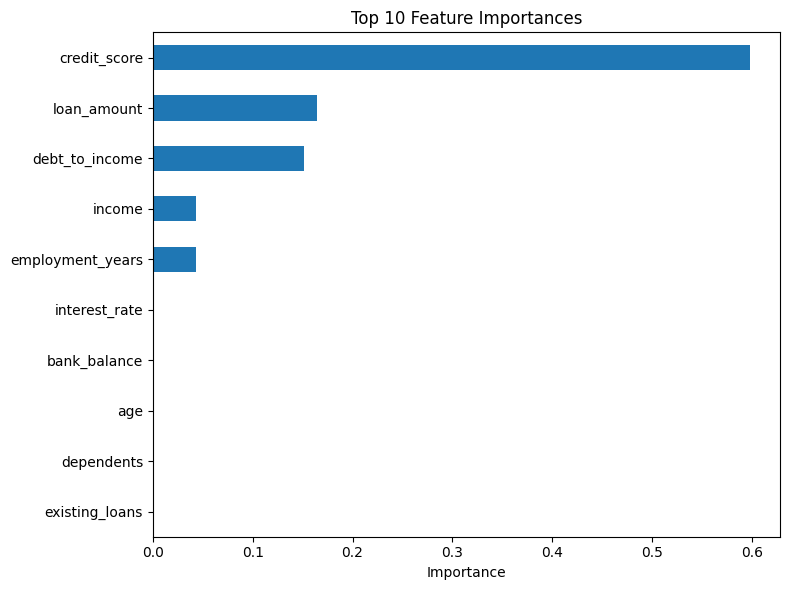

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

importances = pd.Series(
    best.feature_importances_,
    index=X.columns
).nlargest(10).sort_values()

plt.figure(figsize=(8, 6))
importances.plot(kind='barh')
plt.title('Top 10 Feature Importances')
plt.xlabel('Importance')
plt.tight_layout()
plt.show()

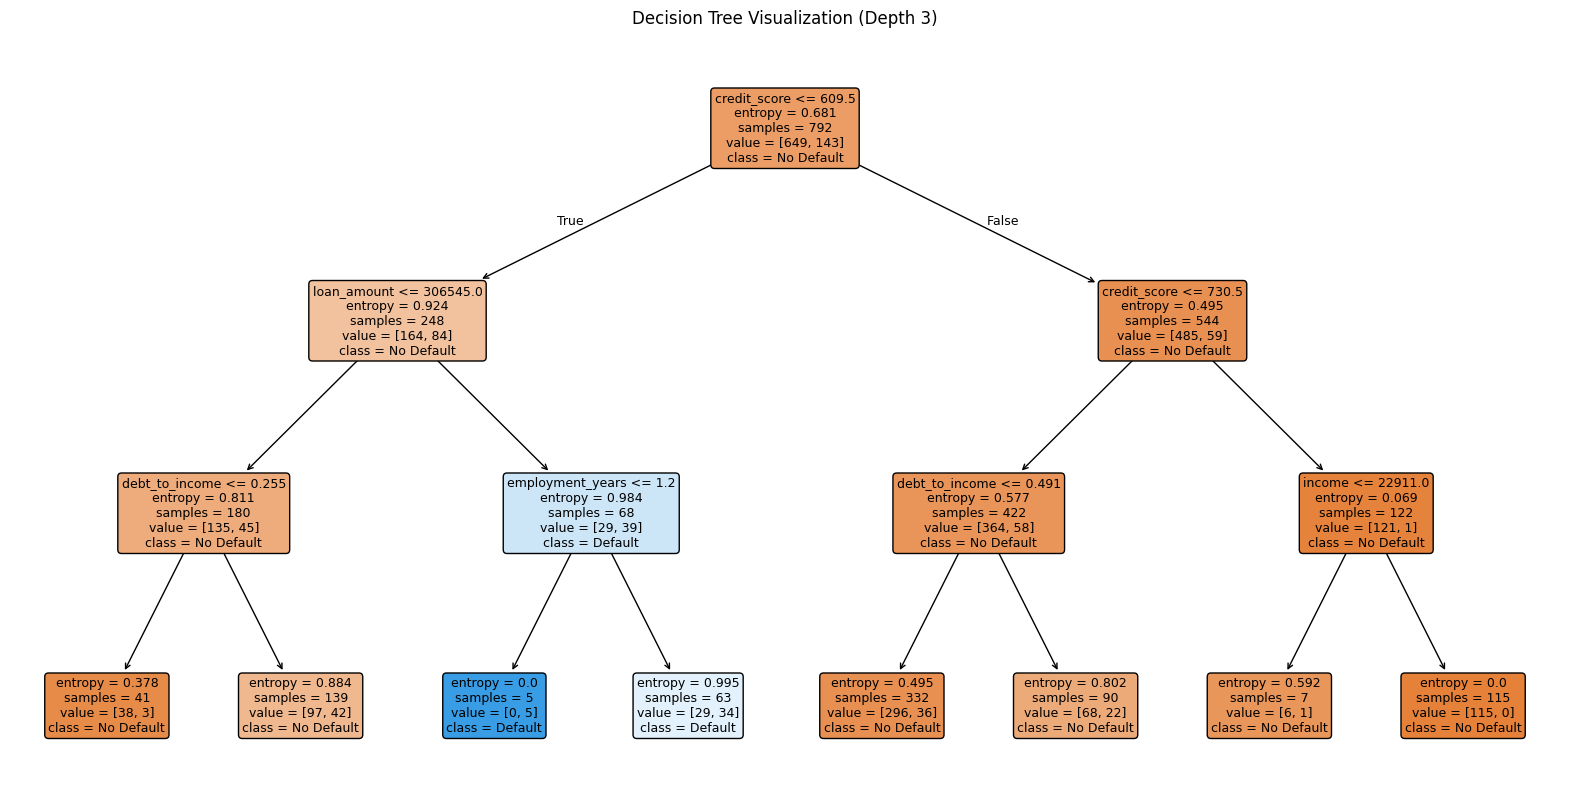

In [ ]:
from sklearn.tree import plot_tree

plt.figure(figsize=(20, 10))

plot_tree(
    best,
    feature_names=X.columns,
    class_names=['No Default', 'Default'],
    filled=True,
    rounded=True,
    max_depth=3,
    fontsize=9
)

plt.title('Decision Tree Visualization (Depth 3)')
plt.show()

In [ ]:
print("Top 5 Features:")
print(
    pd.Series(best.feature_importances_, index=X.columns)
    .nlargest(5)
)

Top 5 Features:
credit_score        0.597969
loan_amount         0.164488
debt_to_income      0.151139
income              0.043222
employment_years    0.043182
dtype: float64


***Question-- List the top five features. Do they match what you saw in Step 4? Explain two decision rules from the tree in plain English.***

Ans--The top five features are the five columns with the highest feature importance values in the trained best Decision Tree. These should be compared with the patterns observed in Step 4 to check whether the findings are consistent. Two decision rules can be explained by following paths through the plotted tree. For example, a rule may state that customers meeting a particular credit-score threshold and having a particular debt-to-income ratio are classified as likely to default. The exact features, thresholds, and predictions must be taken from the actual plotted tree.

# **Conclusion**

The Decision Tree Classifier was used to predict loan defaults based on customer information. The model was evaluated using accuracy, precision, recall, F1-score, and ROC-AUC. Hyperparameter tuning was performed to reduce overfitting and improve performance. Logistic Regression was also compared with the untuned and tuned Decision Tree models. The model can help banks identify customers who may default, but its predictions are not always accurate. Its performance could be improved by using more data and advanced models such as Random Forest.

***Question-- What does the model do well, what are its limitations, and what one thing would you do to improve it (e.g., more data, a Random Forest, different features)?***

Ans-- The model predicts loan defaults using customer financial information and helps identify high-risk applicants. However, it has limitations such as overfitting, class imbalance, and low recall for defaulters, meaning some risky customers may not be identified. To improve performance, I would use a Random Forest Classifier because it combines multiple decision trees, reduces overfitting, and can provide more reliable predictions.